### Week 5 - task
- student name : chanin jung (AI specialization)
- neptun code : Z5XBZP

### Assignment: DBSCAN + Hierarchical Clustering
- Dataset: Use the same numeric/tabular dataset you used previously (the one from the earlier notebook/lecture). Do not use textual data.
- Task type: Unsupervised learning (clustering).
- Submission: One Jupyter Notebook (.ipynb) with code, plots, and short written answers (1-3 sentences each).

#### Constraints
- Use the same cleaned feature matrix across both clustering methods.
- Use a pipeline wherever scaling is needed (especially because both DBSCAN and hierarchical clustering are distance-based).
- All comparisons must use the same clustering evaluation metric (choose one and keep it consistent, e.g. silhouette score).
- Use numeric features only; encode categorical variables if needed.

#### Goal
- Compare two clustering approaches: DBSCAN and Hierarchical Clustering, and determine which gives the best clustering structure for your dataset in terms of separation, interpretability, and practicality.

#### Structure
- **Part A** - Setup + data preparation (one shared `X_scaled` matrix)
- **Part B** - DBSCAN (B1 initial model, B2 parameter exploration)
- **Part C** - Hierarchical clustering (C1 dendrogram, C2 agglomerative clustering)
- **Final** - comparison table + recommendation

### Chosen dataset: Spotify Tracks (same dataset as Week 4)
Same music dataset as the previous assignment (Kaggle *Spotify Tracks Dataset*, local copy `spotify_data.csv`), so the feature matrix stays comparable across assignments.
- **Features (X):** the same 15 numeric features used in Week 4 (`popularity, duration_ms, explicit, danceability, energy, key, loudness, mode, speechiness, acousticness, instrumentalness, liveness, valence, tempo, time_signature`). Textual / ID columns (`track_id, artists, album_name, track_name`) are dropped.
- **Labels:** the same 8 balanced genres (`acoustic, classical, country, edm, heavy-metal, hip-hop, jazz, reggae`, 1000 tracks each, 8000 rows) are kept in a separate variable `y`. In clustering there is no target, so `track_genre` is used **only for post-hoc interpretation** (color / purity checks) and is **never** fed to DBSCAN or to hierarchical clustering.
- **Clustering sample:** both DBSCAN and hierarchical clustering are distance-based; hierarchical clustering needs an O(n^2) distance matrix and the silhouette score is also O(n^2), so clustering runs on a fixed, reproducible **stratified subsample of 3,000 tracks (375 per genre)**. The **exact same** `X_scaled` matrix is reused by every method and every configuration below.

### Part A : Setup + Data Preparation

In [1]:
# ==========================================
# Part A: Setup + Data Preparation
# ==========================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1) Load the dataset (same loader as Week 4: local copy -> works offline)
df = pd.read_csv("spotify_data.csv", encoding="latin-1")
df.columns = [c.replace("\ufeff", "").replace("\u00ef\u00bb\u00bf", "") for c in df.columns]
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
print("Raw shape:", df.shape)

# 2) Drop textual / ID columns (assignment: "Do not use textual data")
df = df.drop(columns=["track_id", "artists", "album_name", "track_name"])

# 3) Encode the only categorical variable: explicit (bool -> 0/1)
df["explicit"] = df["explicit"].astype(int)

# 4) Keep the same 8 balanced genres as Week 4 (interpretation only, not a feature)
GENRES = ["acoustic", "classical", "country", "edm",
          "heavy-metal", "hip-hop", "jazz", "reggae"]
df = df[df["track_genre"].isin(GENRES)].copy()
print("Rows after genre filter:", len(df), "| Columns:", df.shape[1])

# 5) Handle missing values if necessary
missing = df.isnull().sum()
print("Total missing values:", int(missing.sum()))
if int(missing.sum()) > 0:
    df = df.dropna().reset_index(drop=True)
    print("Rows after dropping NaN:", len(df))
else:
    print("-> No missing values, no imputation needed.")

# 6) X = feature matrix (numeric only); y = genre label kept for interpretation only
y_all = df["track_genre"].reset_index(drop=True)
X_all = df.drop(columns=["track_genre"]).reset_index(drop=True)
print("\nX shape:", X_all.shape)
print("Feature dtypes:", {c: str(t) for c, t in X_all.dtypes.items()})

Raw shape: (114000, 20)
Rows after genre filter: 8000 | Columns: 16
Total missing values: 0
-> No missing values, no imputation needed.

X shape: (8000, 15)
Feature dtypes: {'popularity': 'int64', 'duration_ms': 'int64', 'explicit': 'int64', 'danceability': 'float64', 'energy': 'float64', 'key': 'int64', 'loudness': 'float64', 'mode': 'int64', 'speechiness': 'float64', 'acousticness': 'float64', 'instrumentalness': 'float64', 'liveness': 'float64', 'valence': 'float64', 'tempo': 'float64', 'time_signature': 'int64'}


In [2]:
# 7) Reproducible stratified subsample: 375 tracks per genre -> 3,000 tracks.
#    DBSCAN is cheap, but hierarchical clustering and the silhouette score are both
#    O(n^2); the fixed subsample keeps every method fast and directly comparable
#    while still representing all 8 genres equally.
rng = np.random.RandomState(RANDOM_STATE)
PER_GENRE = 375
idx = np.sort(np.concatenate([
    rng.choice(np.where(y_all.values == g)[0], PER_GENRE, replace=False) for g in GENRES
]))
X = X_all.iloc[idx].reset_index(drop=True)
y = y_all.iloc[idx].reset_index(drop=True)
print("Clustering sample:", X.shape)
print("Tracks per genre (balanced):")
print(y.value_counts().sort_index().to_string())

# 8) Standardize inside a Pipeline (scaling is required: both methods are distance-based)
scale_pipe = Pipeline([("scaler", StandardScaler())])
X_scaled = scale_pipe.fit_transform(X)

print("\nX_scaled shape:", X_scaled.shape)
print("Column means after scaling (first 5):", np.round(X_scaled.mean(axis=0), 3)[:5])
print("Column stds  after scaling (first 5):", np.round(X_scaled.std(axis=0), 3)[:5])
print("\nBefore scaling (raw means/stds, first 5 features):")
print(pd.DataFrame({"mean": X.mean().round(2), "std": X.std().round(2)}).head())

Clustering sample: (3000, 15)
Tracks per genre (balanced):
track_genre
acoustic       375
classical      375
country        375
edm            375
heavy-metal    375
hip-hop        375
jazz           375
reggae         375

X_scaled shape: (3000, 15)
Column means after scaling (first 5): [ 0. -0.  0.  0.  0.]
Column stds  after scaling (first 5): [1. 1. 1. 1. 1.]

Before scaling (raw means/stds, first 5 features):
                   mean        std
popularity        25.79      27.11
duration_ms   214295.35  103746.14
explicit           0.09       0.29
danceability       0.57       0.17
energy             0.58       0.28


### Chosen evaluation metric: **silhouette score** (one metric for everything)
I use the **silhouette score** on the standardized data for DBSCAN and for hierarchical clustering alike, so every number in this notebook is directly comparable. It combines cohesion (a point's distance to its own cluster) and separation (its distance to the nearest other cluster) into a single value in [-1, 1], where higher is better. For DBSCAN the score is computed **excluding the -1 noise points**, because noise is not a cluster - this is stated again in Part B.

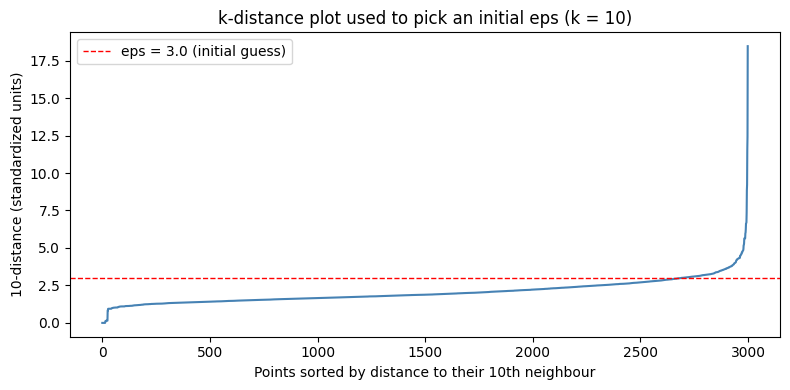

10-distance at the 75th percentile: 2.448
10-distance at the 90th percentile: 3.011
10-distance at the 95th percentile: 3.365


In [3]:
# 9) ONE shared evaluation helper -> the same metric for both methods
def evaluate(Xs, labels):
    # Returns (n_clusters, n_noise, silhouette); noise points (label -1, DBSCAN only)
    # are excluded from the silhouette because noise is not a cluster.
    labels = np.asarray(labels)
    noise = int((labels == -1).sum())
    keep = labels != -1
    Xs_eval, lab_eval = Xs[keep], labels[keep]
    n_clusters = len(set(lab_eval))
    sil = np.nan
    if n_clusters >= 2 and len(lab_eval) > n_clusters:
        sil = float(silhouette_score(Xs_eval, lab_eval))
    return n_clusters, noise, sil


def cluster_sizes(labels):
    labels = np.asarray(labels)
    return np.sort(np.bincount(labels[labels != -1]))[::-1]


# 10) k-distance plot -> a data-driven first guess for DBSCAN's eps
k = 10
nbrs = NearestNeighbors(n_neighbors=k).fit(X_scaled)
dist, _ = nbrs.kneighbors(X_scaled)
k_dist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist, color="steelblue")
plt.axhline(3.0, color="red", ls="--", lw=1, label="eps = 3.0 (initial guess)")
plt.xlabel(f"Points sorted by distance to their {k}th neighbour")
plt.ylabel(f"{k}-distance (standardized units)")
plt.title(f"k-distance plot used to pick an initial eps (k = {k})")
plt.legend()
plt.tight_layout()
plt.show()

for q in [0.75, 0.90, 0.95]:
    print(f"{k}-distance at the {int(q*100)}th percentile: {np.quantile(k_dist, q):.3f}")

### Part B: DBSCAN

##### B1. Initial DBSCAN model

In [4]:
# ----- B1: initial DBSCAN (reasonable starting values from the k-distance plot) -----
t0 = time.time()
labels_db0 = DBSCAN(eps=3.0, min_samples=10).fit_predict(X_scaled)
db0_time = time.time() - t0

n_cl, n_noise, sil = evaluate(X_scaled, labels_db0)
print("Initial DBSCAN parameters : eps = 3.0, min_samples = 10")
print(f"  # clusters (excl. noise) : {n_cl}")
print(f"  # noise points           : {n_noise}  ({n_noise / len(X_scaled) * 100:.1f}% of all points)")
print(f"  silhouette (noise excl.) : {sil:.4f}")
print(f"  cluster sizes            : {list(cluster_sizes(labels_db0))}")
print(f"  runtime                  : {db0_time:.2f}s")

Initial DBSCAN parameters : eps = 3.0, min_samples = 10
  # clusters (excl. noise) : 2
  # noise points           : 118  (3.9% of all points)
  silhouette (noise excl.) : 0.1920
  cluster sizes            : [np.int64(2627), np.int64(255)]
  runtime                  : 0.40s


**B1 result:** with `eps = 3.0` and `min_samples = 10` DBSCAN finds **2 clusters** and flags **118 noise points (3.9%)**, giving a silhouette of **0.192** (noise excluded). So the initial guess already gives a clean 2-cluster solution with a small noise set, and the two clusters are reasonably balanced (2627 vs 255 points).

##### B2. Parameter exploration

In [5]:
# ----- B2: parameter exploration (6 eps x 3 min_samples = 18 combinations) -----
EPS_GRID = [2.5, 2.8, 3.0, 3.2, 3.5, 4.0]
MS_GRID = [5, 10, 20]

rows = []
for eps in EPS_GRID:
    for ms in MS_GRID:
        t0 = time.time()
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl, n_noise, sil = evaluate(X_scaled, labels)
        sizes = cluster_sizes(labels)
        n_eval = len(X_scaled) - n_noise
        rows.append({
            "eps": eps,
            "min_samples": ms,
            "#clusters": n_cl,
            "#noise": n_noise,
            "noise %": round(n_noise / len(X_scaled) * 100, 1),
            "silhouette": round(sil, 4),
            "min cluster %": round(sizes.min() / n_eval * 100, 1) if len(sizes) else np.nan,
            "cluster sizes": list(sizes),
            "runtime (s)": round(time.time() - t0, 2),
        })

db_results = pd.DataFrame(rows).sort_values("silhouette", ascending=False).reset_index(drop=True)
display(db_results)

,eps,min_samples,#clusters,#noise,noise %,silhouette,min cluster %,cluster sizes,runtime (s)
0,4.0,10,2,23,0.8,0.4011,0.9,"[2950, 27]",0.53
1,4.0,5,3,17,0.6,0.3813,0.2,"[2950, 28, 5]",0.54
2,3.5,5,4,26,0.9,0.3554,0.2,"[2943, 17, 9, 5]",0.46
3,3.2,10,2,81,2.7,0.1956,9.2,"[2651, 268]",0.43
4,3.0,10,2,118,3.9,0.1920,8.8,"[2627, 255]",0.42
5,2.8,20,2,242,8.1,0.1919,8.2,"[2533, 225]",0.40
6,2.8,10,2,164,5.5,0.1915,8.6,"[2592, 244]",0.42
7,3.2,20,2,107,3.6,0.1905,8.8,"[2638, 255]",0.44
8,3.0,20,2,146,4.9,0.1891,8.6,"[2609, 245]",0.39
9,3.0,5,6,69,2.3,0.1846,0.2,"[2636, 269, 7, 7, 7, 5]",0.42


In [6]:
# ----- Selection rule (stated explicitly, so the metric cannot be "gamed") -----
# The raw silhouette maximum is NOT automatically the best model: a configuration that
# dumps almost every point into one giant cluster and leaves a handful of singletons
# scores very high but is useless. So the best model is the one with the highest
# silhouette AMONG the configurations whose smallest cluster still holds at least
# 5% of the clustered (non-noise) points.
MIN_SHARE = 5.0

degenerate = db_results[db_results["min cluster %"] < MIN_SHARE]
valid = db_results[db_results["min cluster %"] >= MIN_SHARE]
best_db = valid.sort_values("silhouette", ascending=False).iloc[0]
best_eps, best_ms = float(best_db["eps"]), int(best_db["min_samples"])

print("Rejected as degenerate (smallest cluster < 5% of clustered points):")
display(degenerate[["eps", "min_samples", "#clusters", "#noise", "silhouette",
                    "min cluster %", "cluster sizes"]])

print("\nValid candidates:")
display(valid[["eps", "min_samples", "#clusters", "#noise", "silhouette",
               "min cluster %", "cluster sizes"]])

print(f"\nBEST VALID DBSCAN CONFIGURATION: eps = {best_eps}, min_samples = {best_ms}")
print(f"  # clusters : {int(best_db['#clusters'])}")
print(f"  # noise    : {int(best_db['#noise'])}")
print(f"  silhouette : {best_db['silhouette']:.4f}")

Rejected as degenerate (smallest cluster < 5% of clustered points):


,eps,min_samples,#clusters,#noise,silhouette,min cluster %,cluster sizes
0,4.0,10,2,23,0.4011,0.9,"[2950, 27]"
1,4.0,5,3,17,0.3813,0.2,"[2950, 28, 5]"
2,3.5,5,4,26,0.3554,0.2,"[2943, 17, 9, 5]"
9,3.0,5,6,69,0.1846,0.2,"[2636, 269, 7, 7, 7, 5]"
10,3.2,5,6,47,0.1835,0.2,"[2654, 273, 7, 7, 7, 5]"
11,2.8,5,6,111,0.1814,0.2,"[2611, 255, 7, 6, 5, 5]"
12,2.5,10,3,329,0.1588,0.3,"[2452, 211, 8]"
13,2.5,20,5,537,0.1250,0.3,"[2319, 92, 28, 16, 8]"
14,2.5,5,8,216,0.0968,0.1,"[2520, 234, 6, 5, 5, 5, 5, 4]"



Valid candidates:


,eps,min_samples,#clusters,#noise,silhouette,min cluster %,cluster sizes
3,3.2,10,2,81,0.1956,9.2,"[2651, 268]"
4,3.0,10,2,118,0.1920,8.8,"[2627, 255]"
5,2.8,20,2,242,0.1919,8.2,"[2533, 225]"
6,2.8,10,2,164,0.1915,8.6,"[2592, 244]"
7,3.2,20,2,107,0.1905,8.8,"[2638, 255]"
8,3.0,20,2,146,0.1891,8.6,"[2609, 245]"
15,3.5,10,1,58,NaN,100.0,[2942]
16,3.5,20,1,63,NaN,100.0,[2937]
17,4.0,20,1,51,NaN,100.0,[2949]



BEST VALID DBSCAN CONFIGURATION: eps = 3.2, min_samples = 10
  # clusters : 2
  # noise    : 81
  silhouette : 0.1956


**B2 result / best DBSCAN configuration:** `eps = 3.2`, `min_samples = 10` -> **2 clusters**, **81 noise points (2.7%)**, silhouette **0.196**. The whole sweep takes well under a second per fit (see the runtime column), so tuning DBSCAN is cheap on this dataset.

**How did changing eps affect the number of clusters and noise points?**
Raising `eps` grows every neighbourhood, so blobs merge and fewer points stay "noise": with `min_samples = 5`, going from `eps = 2.5` to `eps = 4.0` shrinks the solution from 8 clusters / 216 noise points to 3 clusters / 17 noise points, i.e. **both the cluster count and the noise count fall as eps grows**. Above roughly `eps = 3.5` DBSCAN collapses into one giant cluster plus tiny fragments (e.g. 2950 + 27 points at `eps = 4.0`, `min_samples = 10`), which *inflates* the silhouette to 0.36-0.40 while being a degenerate solution - exactly why the "smallest cluster >= 5%" filter is applied before choosing the winner.

### Part C: Hierarchical Clustering
Same `X_scaled` matrix, same metric. `scipy.cluster.hierarchy.linkage` is used for the dendrogram and scikit-learn `AgglomerativeClustering` for the configurations.

##### C1. Dendrogram / cluster structure

scipy linkage (ward) on 3000 points: 0.23s


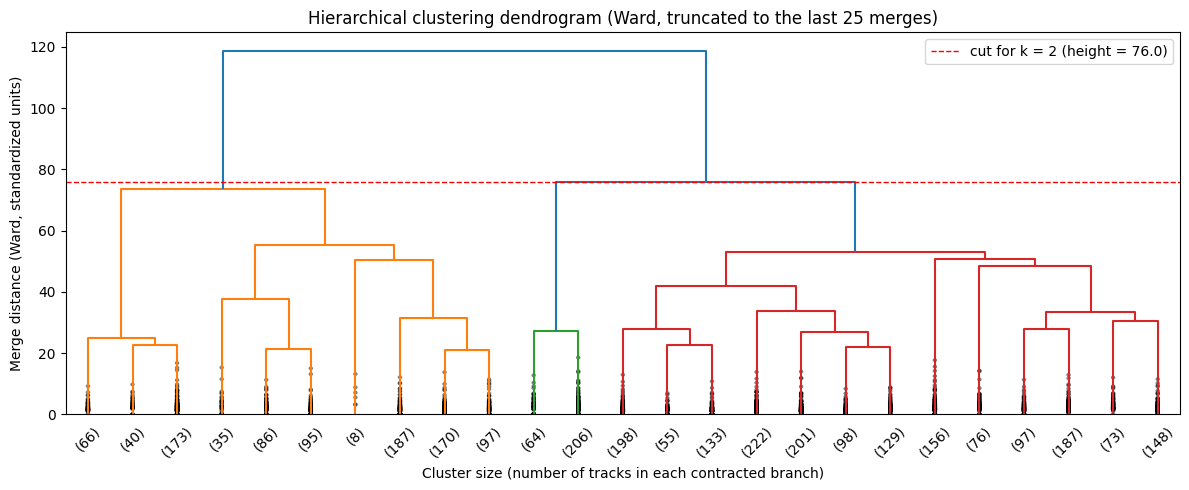

Last 6 merge heights (ward): [ 50.85  53.08  55.18  73.53  75.98 118.78]
Gap between the final merge and the previous one: 42.80


In [7]:
# ----- C1: dendrogram on the SAME scaled data -----
# Ward linkage on the 3,000-point matrix. The dendrogram is truncated to the last
# 25 merges, otherwise a 3,000-leaf plot is unreadable.
t0 = time.time()
Z_ward = linkage(X_scaled, method="ward")
print(f"scipy linkage (ward) on {len(X_scaled)} points: {time.time() - t0:.2f}s")

cut_height = Z_ward[-2, 2]
plt.figure(figsize=(12, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=25, show_contracted=True,
           color_threshold=cut_height)
plt.axhline(cut_height, color="red", ls="--", lw=1,
            label=f"cut for k = 2 (height = {cut_height:.1f})")
plt.title("Hierarchical clustering dendrogram (Ward, truncated to the last 25 merges)")
plt.xlabel("Cluster size (number of tracks in each contracted branch)")
plt.ylabel("Merge distance (Ward, standardized units)")
plt.legend()
plt.tight_layout()
plt.show()

print("Last 6 merge heights (ward):", np.round(Z_ward[-6:, 2], 2))
print(f"Gap between the final merge and the previous one: {Z_ward[-1, 2] - Z_ward[-2, 2]:.2f}")

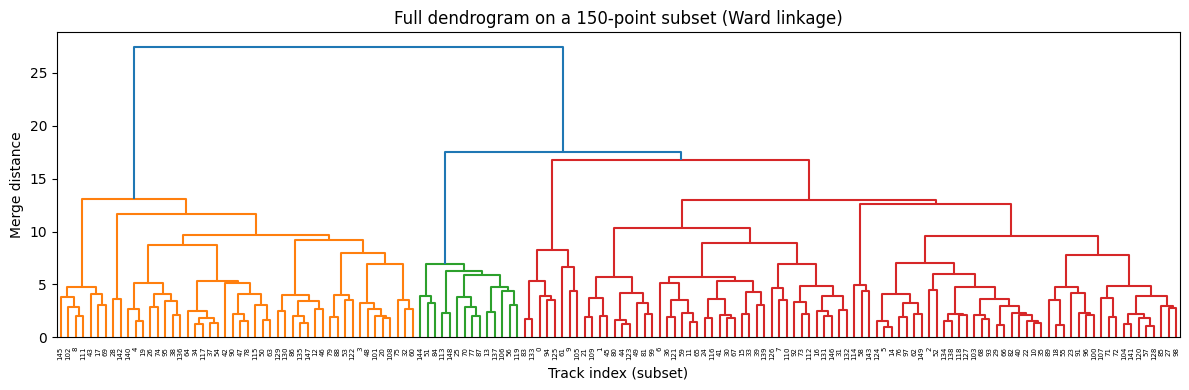

In [8]:
# Full (untruncated) dendrogram on a small 150-point subset, so individual merges are visible
sub_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), 150, replace=False)
Z_sub = linkage(X_scaled[sub_idx], method="ward")

plt.figure(figsize=(12, 4))
dendrogram(Z_sub, color_threshold=Z_sub[-2, 2])
plt.title("Full dendrogram on a 150-point subset (Ward linkage)")
plt.xlabel("Track index (subset)")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()

**C1 interpretation:** the dendrogram shows one very long vertical jump - the last merge height (118.8) sits far above the previous ones (76.0 and 73.5), while all the merges below it are packed between roughly 37 and 55. That means the tracks do **not** form a fine-grained hierarchy: they are two broad blobs that only break into many small, similar fragments after that jump. So I test **k = 2** as the primary cut and k = 3-5 to check whether extra clusters add anything.

##### C2. Agglomerative clustering

In [9]:
# ----- C2: agglomerative clustering = 3 linkage methods x 4 cluster counts -----
LINKAGES = ["ward", "complete", "average"]
K_GRID = [2, 3, 4, 5]

rows = []
for method in LINKAGES:
    for k in K_GRID:
        t0 = time.time()
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X_scaled)
        n_cl, n_noise, sil = evaluate(X_scaled, labels)
        sizes = cluster_sizes(labels)
        rows.append({
            "linkage": method,
            "#clusters": k,
            "silhouette": round(sil, 4),
            "min cluster %": round(sizes.min() / len(labels) * 100, 1),
            "cluster sizes": list(sizes),
            "runtime (s)": round(time.time() - t0, 2),
        })

hier_results = pd.DataFrame(rows)
display(hier_results)

,linkage,#clusters,silhouette,min cluster %,cluster sizes,runtime (s)
0,ward,2,0.1770,31.9,"[2043, 957]",0.33
1,ward,3,0.1679,9.0,"[1773, 957, 270]",0.31
2,ward,4,0.1567,9.0,"[1773, 678, 279, 270]",0.31
3,ward,5,0.1404,7.2,"[1773, 462, 279, 270, 216]",0.30
4,complete,2,0.6315,0.3,"[2992, 8]",0.29
5,complete,3,0.4995,0.1,"[2988, 8, 4]",0.29
6,complete,4,0.4055,0.1,"[2953, 35, 8, 4]",0.29
7,complete,5,0.4050,0.1,"[2953, 35, 6, 4, 2]",0.32
8,average,2,0.7727,0.0,"[2999, 1]",0.28
9,average,3,0.5944,0.0,"[2992, 7, 1]",0.28


In [10]:
# ----- Same selection rule as for DBSCAN (smallest cluster >= 5% of the points) -----
degenerate_h = hier_results[hier_results["min cluster %"] < MIN_SHARE]
valid_h = hier_results[hier_results["min cluster %"] >= MIN_SHARE]
best_h = valid_h.sort_values("silhouette", ascending=False).iloc[0]
best_linkage = best_h["linkage"]
best_k = int(best_h["#clusters"])

print("Rejected as degenerate (smallest cluster < 5% of the points):")
display(degenerate_h[["linkage", "#clusters", "silhouette", "min cluster %", "cluster sizes"]])

print("\nValid candidates:")
display(valid_h[["linkage", "#clusters", "silhouette", "min cluster %", "cluster sizes"]])

print(f"\nBEST VALID HIERARCHICAL CONFIGURATION: linkage = {best_linkage}, k = {best_k}")
print(f"  silhouette : {best_h['silhouette']:.4f}")

Rejected as degenerate (smallest cluster < 5% of the points):


,linkage,#clusters,silhouette,min cluster %,cluster sizes
4,complete,2,0.6315,0.3,"[2992, 8]"
5,complete,3,0.4995,0.1,"[2988, 8, 4]"
6,complete,4,0.4055,0.1,"[2953, 35, 8, 4]"
7,complete,5,0.4050,0.1,"[2953, 35, 6, 4, 2]"
8,average,2,0.7727,0.0,"[2999, 1]"
9,average,3,0.5944,0.0,"[2992, 7, 1]"
10,average,4,0.4985,0.0,"[2988, 7, 4, 1]"
11,average,5,0.4968,0.0,"[2988, 5, 4, 2, 1]"



Valid candidates:


,linkage,#clusters,silhouette,min cluster %,cluster sizes
0,ward,2,0.1770,31.9,"[2043, 957]"
1,ward,3,0.1679,9.0,"[1773, 957, 270]"
2,ward,4,0.1567,9.0,"[1773, 678, 279, 270]"
3,ward,5,0.1404,7.2,"[1773, 462, 279, 270, 216]"



BEST VALID HIERARCHICAL CONFIGURATION: linkage = ward, k = 2
  silhouette : 0.1770


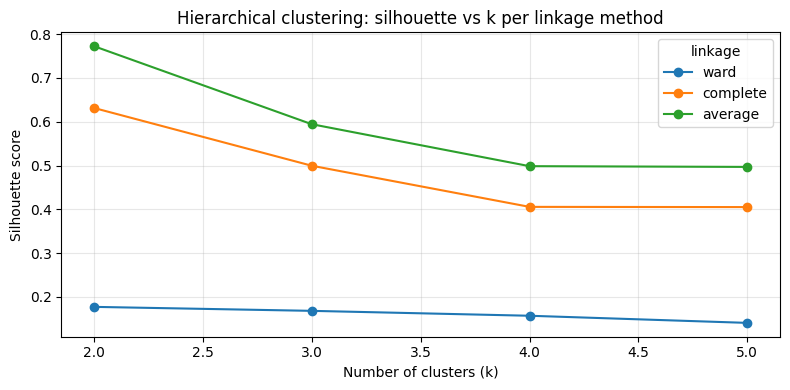

In [11]:
# Silhouette vs k for every linkage method (visual comparison)
plt.figure(figsize=(8, 4))
for method in LINKAGES:
    sub = hier_results[hier_results["linkage"] == method]
    plt.plot(sub["#clusters"], sub["silhouette"], marker="o", label=method)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Hierarchical clustering: silhouette vs k per linkage method")
plt.legend(title="linkage")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**C2 result / best hierarchical configuration:** **Ward linkage, k = 2** -> silhouette **0.177**, with two reasonably balanced clusters (2043 and 957 tracks). This is also the cut suggested by the dendrogram.

**Did different linkage methods produce noticeably different cluster quality?**
Yes, dramatically - but mostly for the wrong reason. `ward` returns balanced clusters at every k, with silhouette falling from 0.177 (k=2) to 0.140 (k=5), whereas `complete` and `average` produce one huge cluster plus a few tiny fragments (e.g. `average`, k=2 -> 2999 + 1 points) and therefore score a fake 0.40-0.77. This happens because single/average-style linkages chain points onto the big blob one by one, and a singleton has a perfect "separation" term, which inflates the silhouette; Ward instead minimises within-cluster variance, so it produces compact, balanced clusters. After applying the same "smallest cluster >= 5%" filter used for DBSCAN, Ward is the only linkage that survives, which is why it is selected.

### Final comparison

In [12]:
# ----- Final comparison table: identical metric (silhouette) on the identical X_scaled -----
labels_db_best = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_scaled)
n_cl_db, noise_db, sil_db = evaluate(X_scaled, labels_db_best)

labels_h_best = AgglomerativeClustering(n_clusters=best_k, linkage=best_linkage).fit_predict(X_scaled)
n_cl_h, noise_h, sil_h = evaluate(X_scaled, labels_h_best)

comparison = pd.DataFrame([
    {
        "Method": "DBSCAN",
        "Configuration": f"eps={best_eps}, min_samples={best_ms}",
        "#clusters": n_cl_db,
        "#noise": noise_db,
        "silhouette": round(sil_db, 4),
        "assigns every point?": "no (noise allowed)",
        "cluster sizes": list(cluster_sizes(labels_db_best)),
    },
    {
        "Method": "Hierarchical (Agglomerative)",
        "Configuration": f"{best_linkage} linkage, k={best_k}",
        "#clusters": n_cl_h,
        "#noise": noise_h,
        "silhouette": round(sil_h, 4),
        "assigns every point?": "yes",
        "cluster sizes": list(cluster_sizes(labels_h_best)),
    },
])
display(comparison)

,Method,Configuration,#clusters,#noise,silhouette,assigns every point?,cluster sizes
0,DBSCAN,"eps=3.2, min_samples=10",2,81,0.1956,no (noise allowed),"[2651, 268]"
1,Hierarchical (Agglomerative),"ward linkage, k=2",2,0,0.1770,yes,"[2043, 957]"


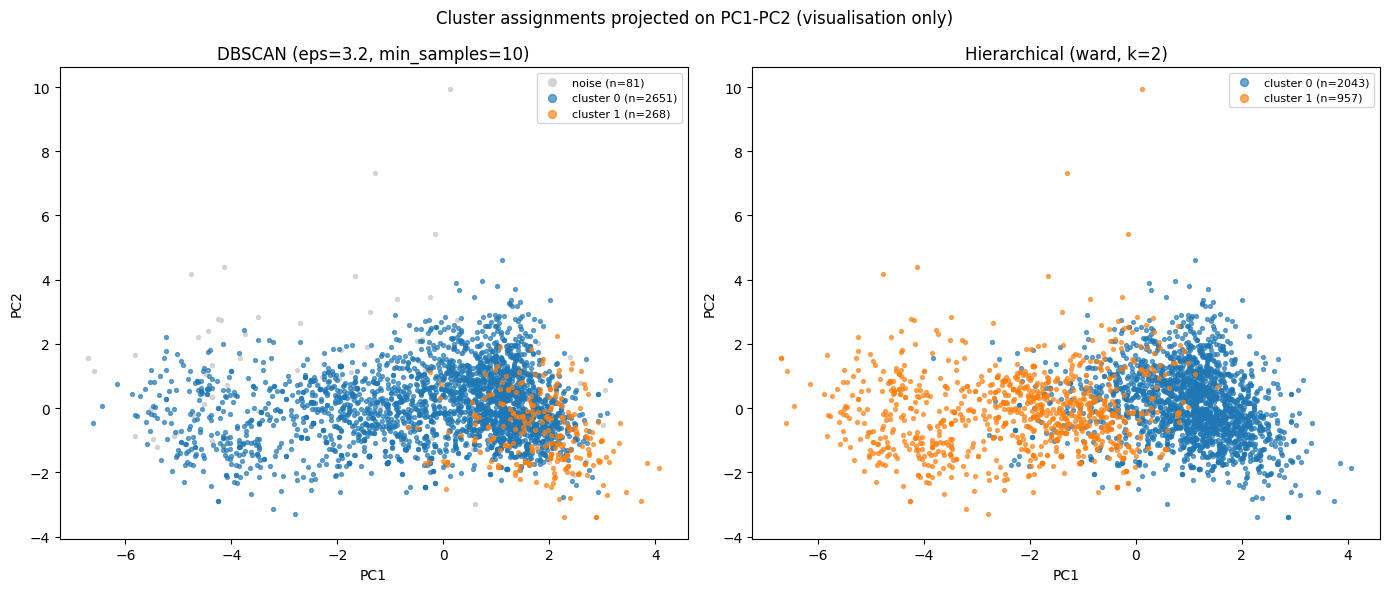

In [13]:
# ----- Visual comparison on PC1-PC2 (2D view only; clustering used all 15 features) -----
X_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, labels, title in [
    (axes[0], labels_db_best, f"DBSCAN (eps={best_eps}, min_samples={best_ms})"),
    (axes[1], labels_h_best, f"Hierarchical ({best_linkage}, k={best_k})"),
]:
    if (labels == -1).any():
        m = labels == -1
        ax.scatter(X_2d[m, 0], X_2d[m, 1], s=8, c="lightgrey", label=f"noise (n={m.sum()})")
    for c in sorted(set(labels)):
        if c == -1:
            continue
        m = labels == c
        ax.scatter(X_2d[m, 0], X_2d[m, 1], s=8, alpha=0.65, label=f"cluster {c} (n={m.sum()})")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8, markerscale=2)
plt.suptitle("Cluster assignments projected on PC1-PC2 (visualisation only)")
plt.tight_layout()
plt.show()

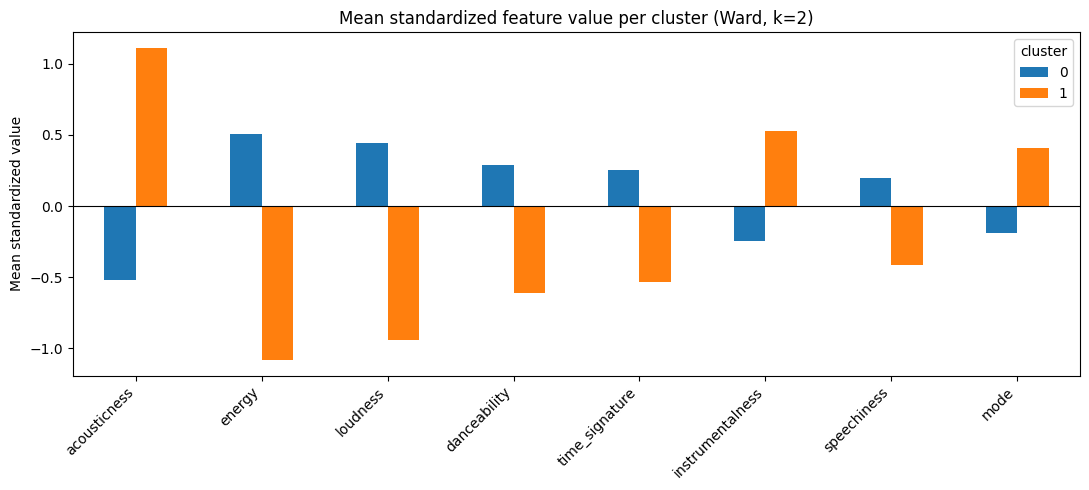

Genre composition of the hierarchical clusters (track_genre was NOT used for clustering):


track_genre,acoustic,classical,country,edm,heavy-metal,hip-hop,jazz,reggae
cluster,,,,,,,,
0,187,34,261,364,353,353,120,371
1,188,341,114,11,22,22,255,4


Genre composition of the DBSCAN clusters (label -1 = noise):


track_genre,acoustic,classical,country,edm,heavy-metal,hip-hop,jazz,reggae
dbscan label,,,,,,,,
-1,5,38,1,1,4,18,13,1
0,350,337,364,336,335,255,361,313
1,20,0,10,38,36,102,1,61


In [14]:
# ----- What do the clusters actually mean? (interpretability check) -----
profile = pd.DataFrame(X_scaled, columns=X.columns)
profile["cluster"] = labels_h_best
means = profile.groupby("cluster").mean()
top_features = means.abs().max().sort_values(ascending=False).head(8).index

means[top_features].T.plot(kind="bar", figsize=(11, 5))
plt.title(f"Mean standardized feature value per cluster (Ward, k={best_k})")
plt.ylabel("Mean standardized value")
plt.axhline(0, color="black", lw=0.8)
plt.xticks(rotation=45, ha="right")
plt.legend(title="cluster")
plt.tight_layout()
plt.show()

print("Genre composition of the hierarchical clusters (track_genre was NOT used for clustering):")
display(pd.crosstab(labels_h_best, y, rownames=["cluster"], colnames=["track_genre"]))
print("Genre composition of the DBSCAN clusters (label -1 = noise):")
display(pd.crosstab(labels_db_best, y, rownames=["dbscan label"], colnames=["track_genre"]))

### Final answer
Both methods agree that this dataset has a **weak, essentially two-blob structure**: the best valid DBSCAN configuration (`eps=3.2`, `min_samples=10` -> 2 clusters + 2.7% noise, silhouette 0.196) and the best valid hierarchical configuration (Ward, k=2 -> 2 clusters, silhouette 0.177) score almost identically, and both recover the same intuitive split - a "quiet/acoustic" group (classical, jazz, acoustic) versus a "loud/rhythmic" group (edm, heavy-metal, hip-hop, reggae, country). Cluster *quality* is therefore basically a tie, and neither method finds well-separated clusters (a silhouette of ~0.2 means the blobs overlap heavily).

For **robustness**, hierarchical clustering wins: Ward is deterministic, needs no parameter grid, and assigns every track, whereas DBSCAN's solution changes qualitatively with `eps` (two balanced clusters at `eps=3.2`, but a degenerate 2950 + 27 split at `eps=4.0`) and discards 2.7% of the tracks as noise. For **interpretability**, Ward is also ahead here, because the dendrogram gives one readable justification for k = 2 and the cluster profiles are easy to describe, while DBSCAN's added value is its noise flag rather than a better partition. **Recommendation:** use **Ward hierarchical clustering with k = 2** as the primary model for this dataset (robust, interpretable, uses all the data), and keep **DBSCAN (`eps=3.2`, `min_samples=10`) as a complementary outlier detector**, since its 81 noise points are mostly the ambiguous boundary tracks (38 classical, 18 hip-hop and 13 jazz tracks that sit between the two blobs).